<a href="https://colab.research.google.com/github/Divyansh-2024/Blinkit-Grocery-Sales-Analysis/blob/main/tesla_stock_price_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Here we are analyzing the tesla stock data and train theml models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("TSLA.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800,5.000,3.508,4.778,4.778,93831500
1,2010-06-30,5.158,6.084,4.660,4.766,4.766,85935500
2,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000
3,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000
4,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2956 entries, 0 to 2955
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2956 non-null   object 
 1   Open       2956 non-null   float64
 2   High       2956 non-null   float64
 3   Low        2956 non-null   float64
 4   Close      2956 non-null   float64
 5   Adj Close  2956 non-null   float64
 6   Volume     2956 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 161.8+ KB


In [4]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2956.000000,2956.000000,2956.000000,2956.000000,2956.000000,2.956000e+03
mean,138.691296,141.771603,135.425953,138.762183,138.762183,3.131449e+07
std,250.044839,255.863239,243.774157,250.123115,250.123115,2.798383e+07
min,3.228000,3.326000,2.996000,3.160000,3.160000,5.925000e+05
25%,19.627000,20.402000,19.127500,19.615000,19.615000,1.310288e+07
50%,46.656999,47.487001,45.820002,46.545000,46.545000,2.488680e+07
75%,68.057001,69.357500,66.911501,68.103998,68.103998,3.973875e+07
max,1234.410034,1243.489990,1217.000000,1229.910034,1229.910034,3.046940e+08


In [5]:

df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [6]:
df.shape

(2956, 7)

Plotting of the data

Text(0, 0.5, 'Tesla Open')

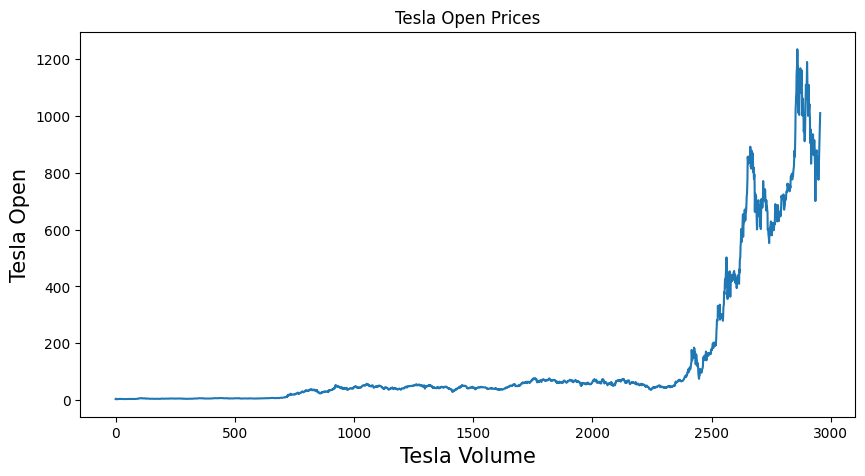

In [7]:
plt.figure(figsize=(10,5))
plt.plot(df["Open"])
plt.title("Tesla Open Prices")
plt.xlabel("Tesla Volume", fontsize=15)
plt.ylabel("Tesla Open", fontsize=15)


Text(0, 0.5, 'Close Price')

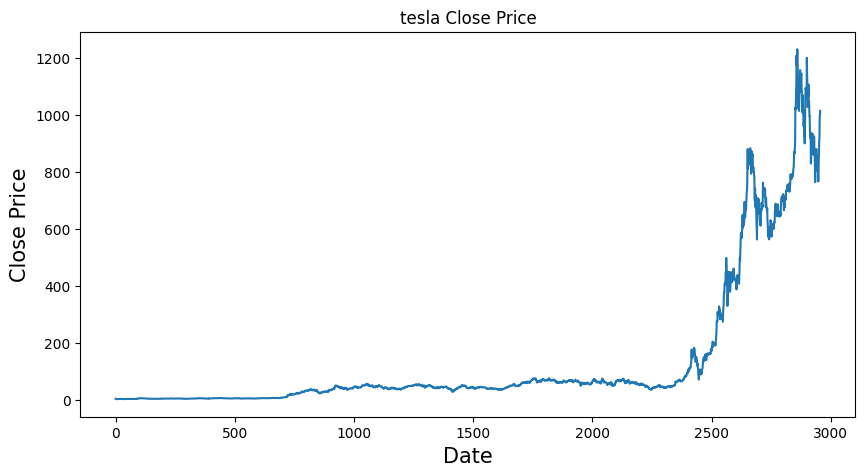

In [8]:
# Close Price
plt.figure(figsize=(10,5))
plt.plot(df["Close"])
plt.title("tesla Close Price")
plt.xlabel("Date",fontsize=15)
plt.ylabel("Close Price", fontsize=15)

### Improving the Plots
We will convert the `Date` column to datetime objects and use it on the x-axis to make the plots accurate and professional.

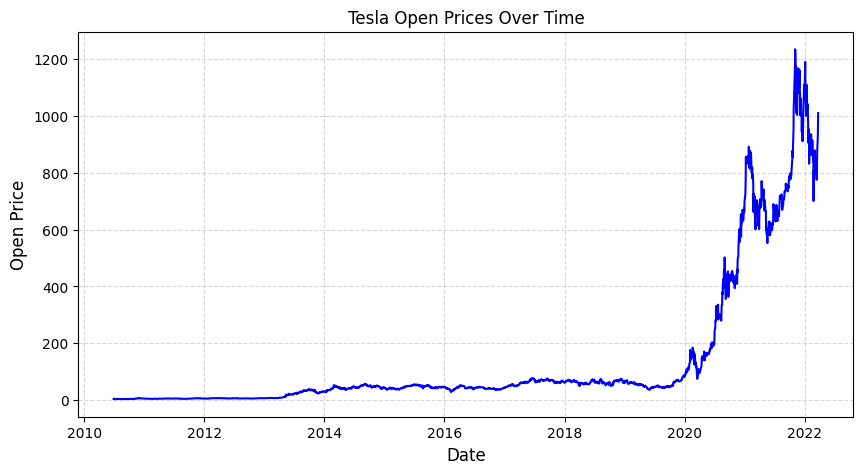

In [9]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Corrected Tesla Open Prices plot
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Open"], color='blue')
plt.title("Tesla Open Prices Over Time")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Open Price", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

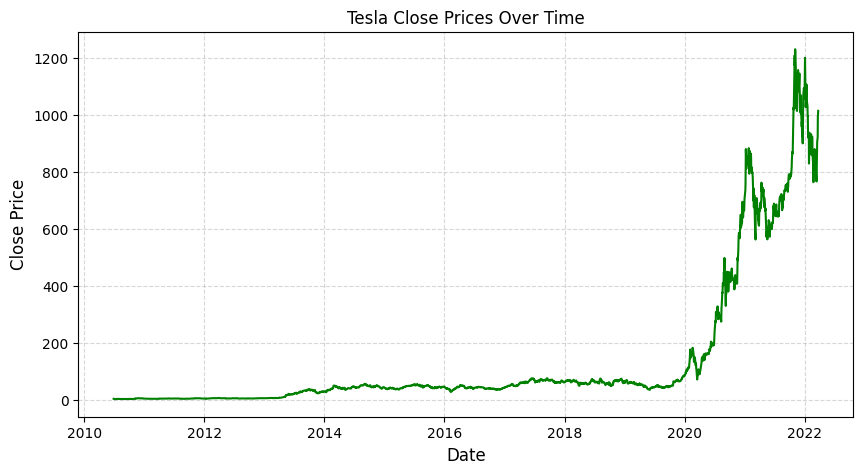

In [10]:
# Corrected Tesla Close Prices plot
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Close"], color='green')
plt.title("Tesla Close Prices Over Time")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Close Price", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Text(0, 0.5, 'Close Price')

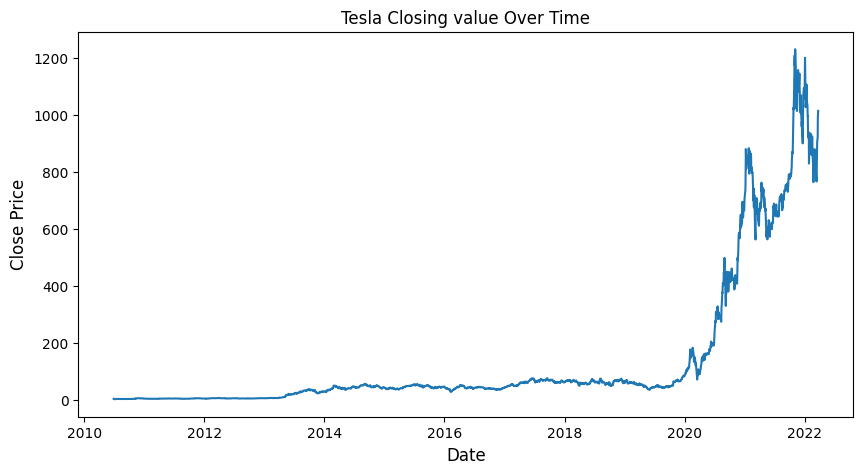

In [11]:
df["Date"]=pd.to_datetime(df["Date"])
plt.figure(figsize=(10,5))
plt.plot(df["Date"], df["Close"])
plt.title("Tesla Closing value Over Time")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Close Price", fontsize=12)

Text(0, 0.5, 'Close Price')

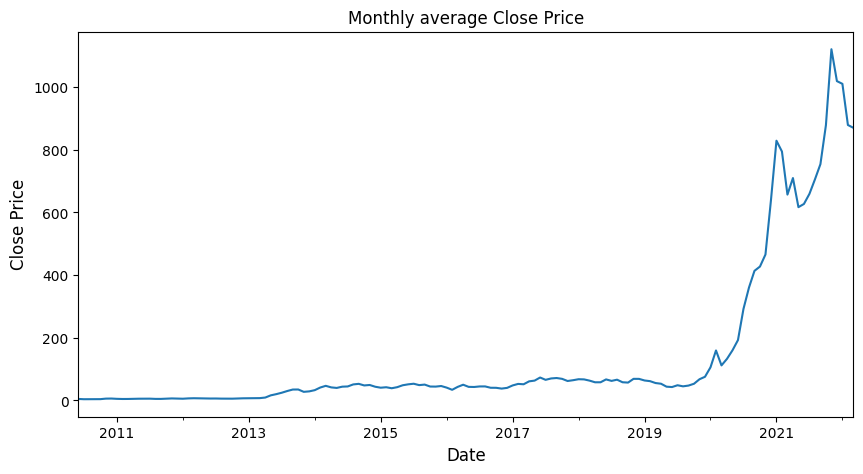

In [12]:
# Monthly Average

df['Month']=df['Date'].dt.to_period('M')
montly_avg_close=df.groupby('Month')['Close'].mean()

plt.figure(figsize=(10,5))
montly_avg_close.plot()
plt.title("Monthly average Close Price")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Close Price", fontsize=12)


In [13]:
df1=pd.read_csv('TSLA.csv')
df1.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800,5.000,3.508,4.778,4.778,93831500
1,2010-06-30,5.158,6.084,4.660,4.766,4.766,85935500
2,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000
3,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000
4,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500


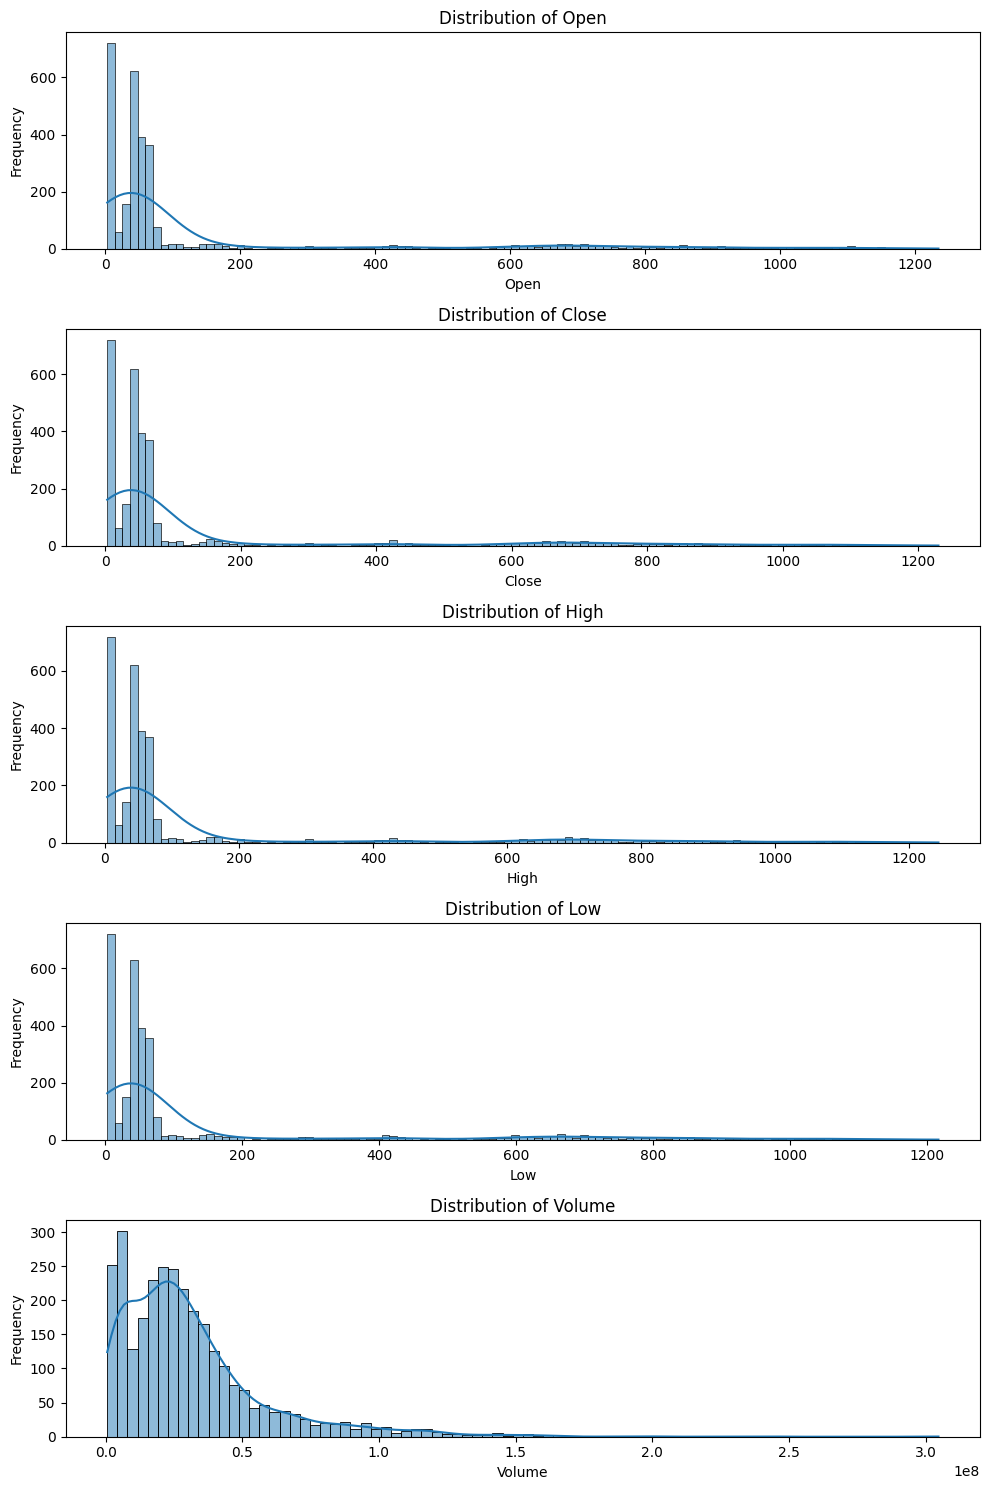

In [14]:
features_to_plot=['Open','Close','High','Low','Volume']
fig,axes=plt.subplots(len(features_to_plot),1,figsize=(10,15))


for i, feature in enumerate(features_to_plot):
  sns.histplot(df1[feature],ax=axes[i],kde=True)
  axes[i].set_title(f'Distribution of {feature}')
  axes[i].set_xlabel(feature)
  axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

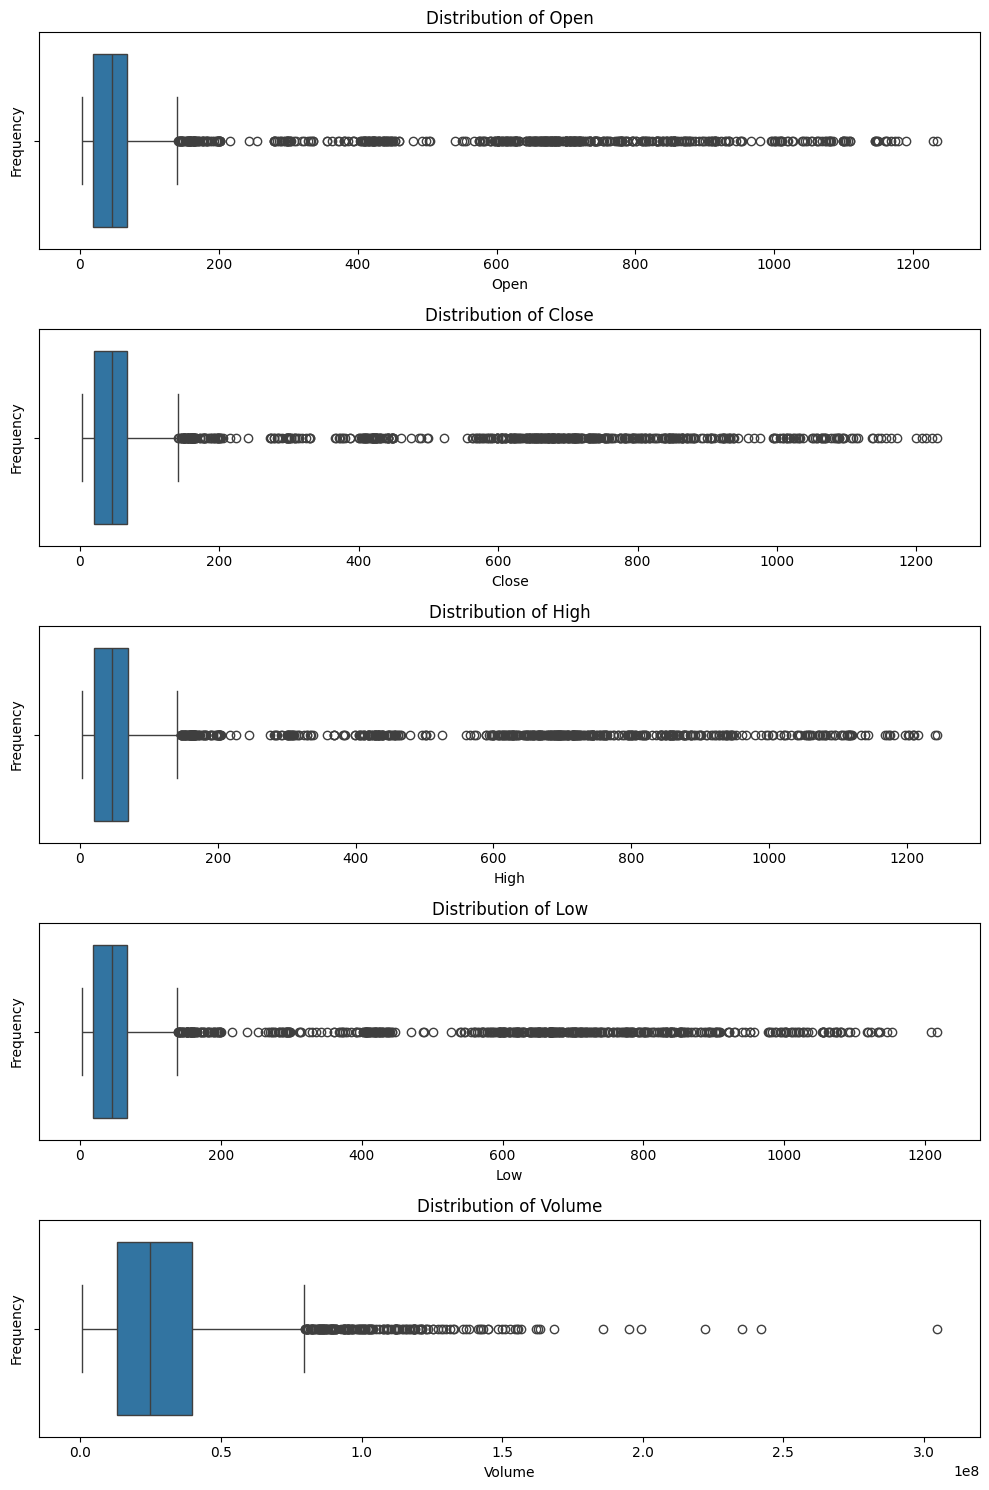

In [15]:
# Box plot used to understand outliers

features_to_plot=['Open','Close','High','Low','Volume']
fig,axes=plt.subplots(len(features_to_plot),1,figsize=(10,15))


for i, feature in enumerate(features_to_plot):
  sns.boxplot(x=df1[feature],ax=axes[i])
  axes[i].set_title(f'Distribution of {feature}')
  axes[i].set_xlabel(feature)
  axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()
#

In [16]:
# Dropping adjacent close column
df1.drop('Adj Close', axis=1, inplace=True)


In [17]:
df1['Date']=pd.to_datetime(df1['Date'])
df1['Day']=df1['Date'].dt.day

In [18]:
df1['Month']=df1['Date'].dt.month
df1['Year']=df1['Date'].dt.year

In [20]:
from pandas.tseries.offsets import QuarterBegin
quartelrly_end_month_list=[3,6,9,12]
df1['is_quarter_end']=df1['Month'].apply(lambda x: 1 if x in quartelrly_end_month_list else 0)


In [21]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume,Month
0,2010-06-29,3.800,5.000,3.508,4.778,4.778,93831500,2010-06
1,2010-06-30,5.158,6.084,4.660,4.766,4.766,85935500,2010-06
2,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000,2010-07
3,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000,2010-07
4,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500,2010-07


In [24]:
yearly_ohlc = df1.groupby('Year')[["Open","High","Low","Close"]].mean()

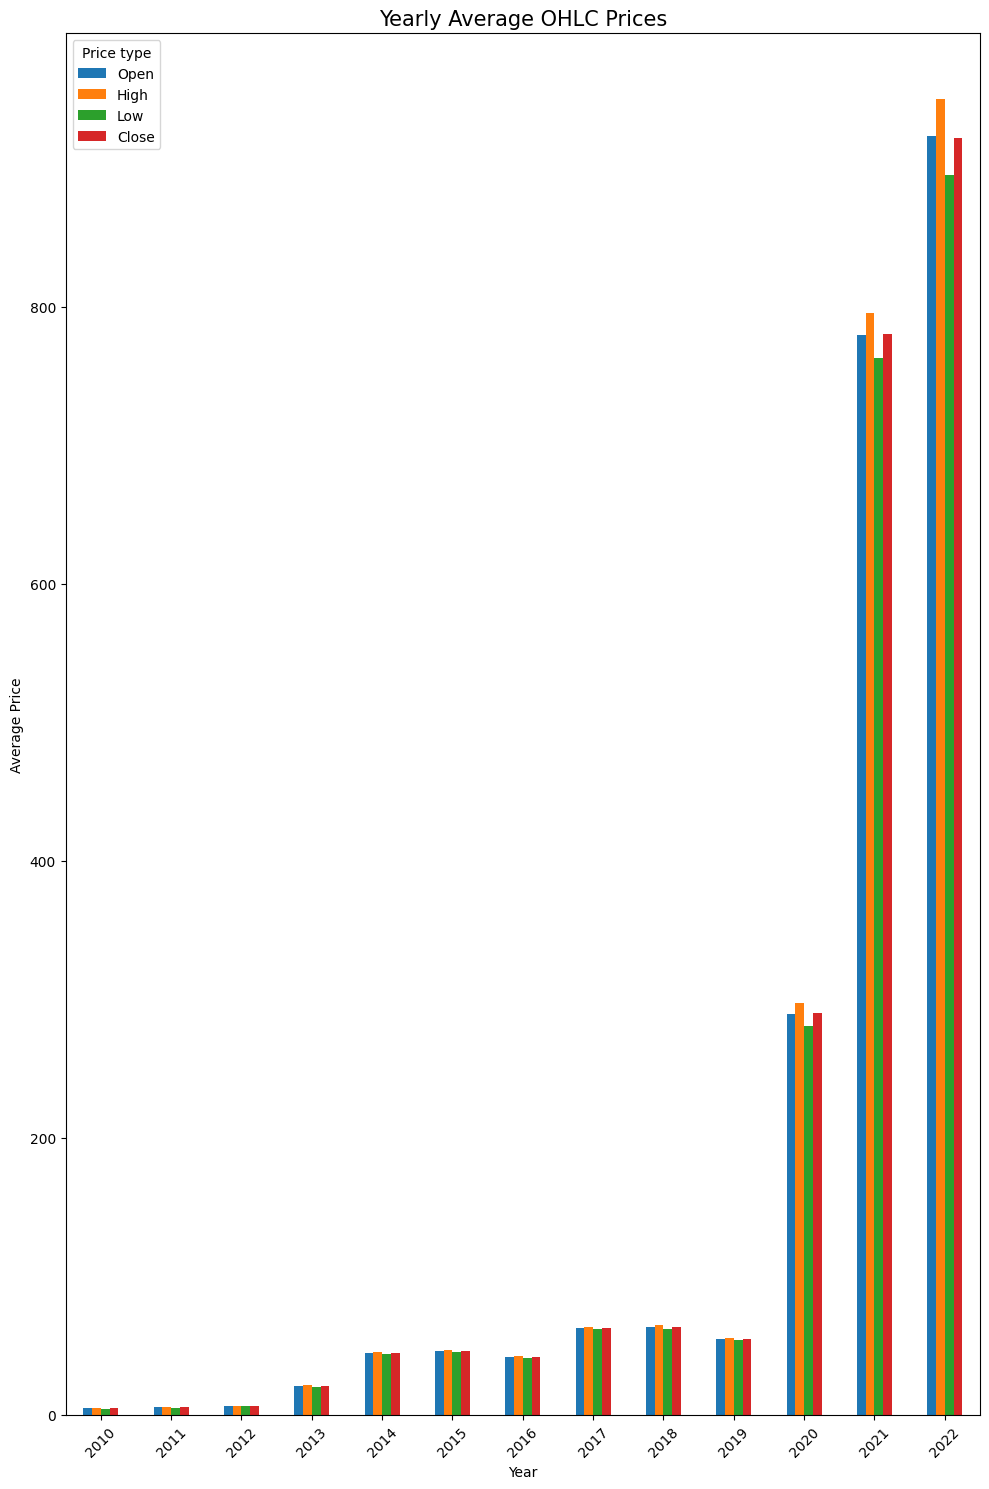

In [26]:
yearly_ohlc.plot(kind='bar',figsize=(10,15))
plt.title("Yearly Average OHLC Prices", fontsize = 15)
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.legend(title="Price type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
quarter_performance=df1.groupby('is_quarter_end')[["Open","High","Low","Close"]].mean()

In [28]:
df1['Open-Close']=df1['Open']-df1['Close']
df1['High-Low']=df1['High']-df1['Low']
df1['target']=np.where(df1['Close'].shift(-1)>df1['Close'],1,0)

In [29]:
df1.head()

,Date,Open,High,Low,Close,Volume,Day,Month,Year,is_quarter_end,Open-Close,High-Low,target
0,2010-06-29,3.800,5.000,3.508,4.778,93831500,29,6,2010,1,-0.978,1.492,0
1,2010-06-30,5.158,6.084,4.660,4.766,85935500,30,6,2010,1,0.392,1.424,0
2,2010-07-01,5.000,5.184,4.054,4.392,41094000,1,7,2010,0,0.608,1.130,0
3,2010-07-02,4.600,4.620,3.742,3.840,25699000,2,7,2010,0,0.760,0.878,0
4,2010-07-06,4.000,4.000,3.166,3.222,34334500,6,7,2010,0,0.778,0.834,0


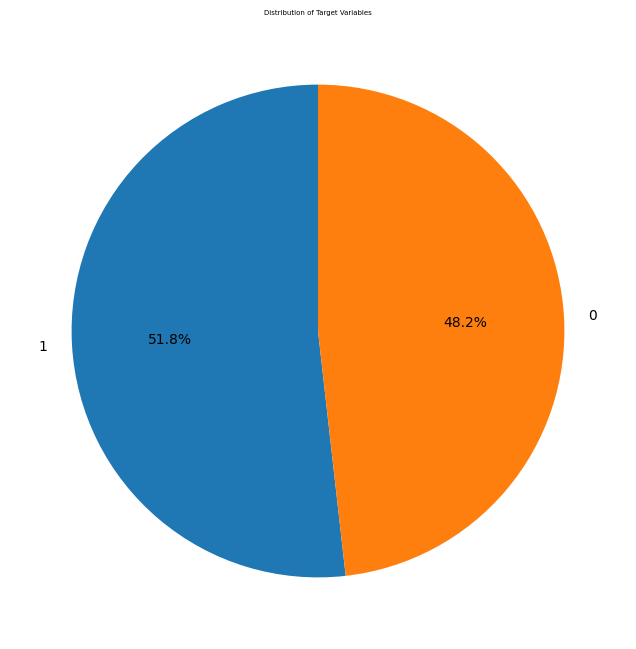

In [33]:
# Distribution of target variables pie chart

target_counts = df1['target'].value_counts()
plt.figure(figsize=(8,8))
plt.pie(target_counts, labels=target_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Target Variables', fontsize=5)
plt.show()

Text(0.5, 1.0, 'Correlation Matrix')

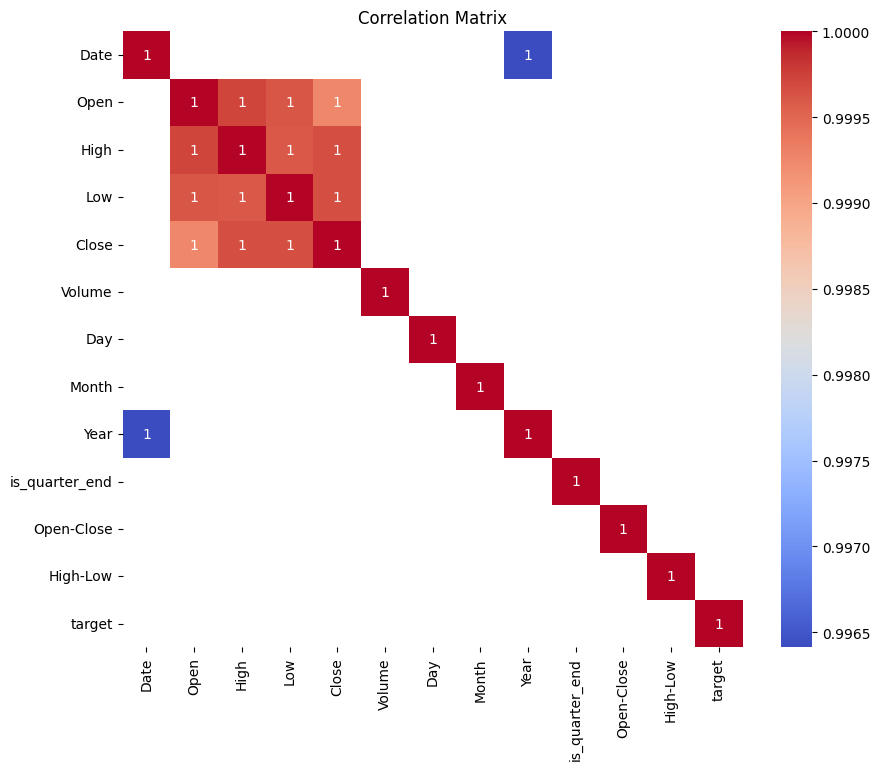

In [35]:
#  very important for interview
corr_matrix=df1.corr()
plt.figure(figsize=(10,8))

#  create a mask for values less than 0.9
mask=corr_matrix.abs()<0.90

sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',mask=mask)
plt.title('Correlation Matrix')


# Model Building

In [36]:
# SKlearn processing
# Data splitting and memorization
# Training and testing data splitting
#  it is a fixed syntax for training and testing data splitting
from sklearn.model_selection import train_test_split


In [37]:
# Standard Scaler

from sklearn.preprocessing import StandardScaler

In [38]:
# Define features
features=['Open','Close','Low','High','Open-Close','High-Low','is_quarter_end']
target='target'

In [39]:
available_feature=[col for col in features if col in df1.columns]

In [40]:
x=df1[available_feature]
y=df1[target]

In [41]:
# Split data into training and testing data
X_train, X_test, Y_train, Y_test = train_test_split(x,y,test_size=0.1,random_state=42)

In [43]:
# Normalize the features
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [45]:
print("Data Splitting and normalization completed with 80-20 ratio")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_train shape: {Y_train.shape}")

Data Splitting and normalization completed with 80-20 ratio
X_train shape: (2660, 7)
X_test shape: (296, 7)
Y_train shape: (2660,)


In [46]:
# Import necessary models for evaluation

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [48]:
log_reg_model=LogisticRegression(random_state=42)
svm_model=SVC(random_state=42)
dt_model=DecisionTreeClassifier(random_state=42)
rf_model=RandomForestClassifier(random_state=42)

In [49]:
# Model traing using logi. regression
log_reg_model=log_reg_model.fit(X_train,Y_train)


In [50]:
# Predict on training data
y_pred=log_reg_model.predict(X_test)


In [51]:
train_accuracy_log_reg=log_reg_model.score(X_train, Y_train)

In [52]:
test_accuracy_log_reg=log_reg_model.score(X_test,Y_test)

In [53]:
print('Logistic Regression')
print(f'Training Accuracy: {train_accuracy_log_reg}')
print(f'Testing Accuracy: {test_accuracy_log_reg}')

Logistic Regression
Training Accuracy: 0.5191729323308271
Testing Accuracy: 0.527027027027027


In [56]:
# Process is same for svm,dt,rf
svm_model=svm_model.fit(X_train,Y_train)
svm_pred=svm_model.predict(X_test)
train_accuracy_svm=svm_model.score(X_train,Y_train)
test_accuracy_svm=svm_model.score(X_test,Y_test)
print('SVM Model')
print(f'Training Accuracy:{train_accuracy_svm}')
print(f'Testing Accuracy:{test_accuracy_svm}')

SVM Model
Training Accuracy:0.5304511278195488
Testing Accuracy:0.5405405405405406


In [57]:
dt_model=dt_model.fit(X_train,Y_train)
dt_pred=dt_model.predict(X_test)
train_accuracy_dt=dt_model.score(X_train,Y_train)
test_accuracy_dt=dt_model.score(X_test,Y_test)
print('Decision Tree Model')
print(f'Training Accuracy:{train_accuracy_dt}')
print(f'Testing Accuracy:{test_accuracy_dt}')

Decision Tree Model
Training Accuracy:1.0
Testing Accuracy:0.5101351351351351


In [59]:
rf_model = rf_model.fit(X_train, Y_train)
rf_pred = rf_model.predict(X_test)
train_accuracy_rf = rf_model.score(X_train, Y_train)
test_accuracy_rf = rf_model.score(X_test, Y_test)

print('Random Forest Model')
print(f'Training Accuracy: {train_accuracy_rf}')
print(f'Testing Accuracy: {test_accuracy_rf}')

Random Forest Model
Training Accuracy: 1.0
Testing Accuracy: 0.4797297297297297


### Overfitting रोकने के लिए Hyperparameter Tuning (Pruning)

In [60]:
# tuned Decision Tree
tuned_dt = DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)
tuned_dt.fit(X_train, Y_train)

# tuned Random Forest
tuned_rf = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_split=10, random_state=42)
tuned_rf.fit(X_train, Y_train)

print('--- Tuned Decision Tree ---')
print(f'Train Accuracy: {tuned_dt.score(X_train, Y_train):.4f}')
print(f'Test Accuracy: {tuned_dt.score(X_test, Y_test):.4f}')

print('\n--- Tuned Random Forest ---')
print(f'Train Accuracy: {tuned_rf.score(X_train, Y_train):.4f}')
print(f'Test Accuracy: {tuned_rf.score(X_test, Y_test):.4f}')

--- Tuned Decision Tree ---
Train Accuracy: 0.5699
Test Accuracy: 0.5439

--- Tuned Random Forest ---
Train Accuracy: 0.6226
Test Accuracy: 0.4730


### Feature Engineering: Adding Technical Indicators

In [61]:
# Creating copy to avoid side effects
df_feat = df1.copy()

# Calculate Moving Averages
df_feat['SMA_5'] = df_feat['Close'].rolling(window=5).mean()
df_feat['SMA_10'] = df_feat['Close'].rolling(window=10).mean()

# Calculate Daily Return Percent
df_feat['Daily_Return'] = df_feat['Close'].pct_change()

# Drop NaN values created by rolling windows
df_feat.dropna(inplace=True)

# Update feature list and target
new_features = ['Open', 'Close', 'Low', 'High', 'Open-Close', 'High-Low', 'is_quarter_end', 'SMA_5', 'SMA_10', 'Daily_Return']
X_new = df_feat[new_features]
Y_new = df_feat['target']

# Train-Test Split (90-10 ratio)
X_train_n, X_test_n, Y_train_n, Y_test_n = train_test_split(X_new, Y_new, test_size=0.1, random_state=42)

# Normalize features
scaler_n = StandardScaler()
X_train_scaled = scaler_n.fit_transform(X_train_n)
X_test_scaled = scaler_n.transform(X_test_n)

# Train tuned Decision Tree on new features
new_dt = DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)
new_dt.fit(X_train_scaled, Y_train_n)

print('--- Tuned DT with Technical Indicators ---')
print(f'New Train Accuracy: {new_dt.score(X_train_scaled, Y_train_n):.4f}')
print(f'New Test Accuracy: {new_dt.score(X_test_scaled, Y_test_n):.4f}')

--- Tuned DT with Technical Indicators ---
New Train Accuracy: 0.5256
New Test Accuracy: 0.5525


### Training XGBoost Classifier on Technical Indicators

In [62]:
from xgboost import XGBClassifier

# Initialize XGBoost with some regularization parameters to avoid overfitting
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

# Train the model
xgb_model.fit(X_train_scaled, Y_train_n)

# Calculate accuracies
train_acc_xgb = xgb_model.score(X_train_scaled, Y_train_n)
test_acc_xgb = xgb_model.score(X_test_scaled, Y_test_n)

print('--- XGBoost Classifier ---')
print(f'Train Accuracy: {train_acc_xgb:.4f}')
print(f'Test Accuracy: {test_acc_xgb:.4f}')

--- XGBoost Classifier ---
Train Accuracy: 0.6810
Test Accuracy: 0.4847


### Fixing Overfitting in XGBoost (Hyperparameter Regularization)

In [63]:
# Initialize XGBoost with strict regularization to prevent overfitting
regularized_xgb = XGBClassifier(
    n_estimators=50,          # Reduced estimators
    max_depth=2,              # Very shallow trees to prevent memorizing noise
    learning_rate=0.01,       # Lower learning rate for robust steps
    min_child_weight=5,       # Requires more samples to create a node split
    gamma=1.0,                # Minimum loss reduction required to make a split
    random_state=42,
    eval_metric='logloss'
)

# Train the regularized model
regularized_xgb.fit(X_train_scaled, Y_train_n)

# Calculate regularized accuracies
train_acc_reg = regularized_xgb.score(X_train_scaled, Y_train_n)
test_acc_reg = regularized_xgb.score(X_test_scaled, Y_test_n)

print('--- Regularized XGBoost Classifier ---')
print(f'New Train Accuracy: {train_acc_reg:.4f}')
print(f'New Test Accuracy: {test_acc_reg:.4f}')

--- Regularized XGBoost Classifier ---
New Train Accuracy: 0.5196
New Test Accuracy: 0.5458
